# Applied Machine Learning Laboratory
# Lab: K-Means Clustering

**Environment:** Google Colab / Jupyter Notebook  
**Primary dataset:** UCI Wine Recognition Dataset  
**Learning mode:** Unsupervised learning

## Learning outcomes

By the end of this laboratory, students should be able to:

1. Explain the objective and iterative procedure of K-Means.
2. Explain why feature scaling is essential for distance-based algorithms.
3. Fit and interpret a K-Means clustering model.
4. Select a plausible number of clusters using the Elbow Method and Silhouette Analysis.
5. Visualize high-dimensional clusters using PCA.
6. Evaluate clusters using internal metrics and, only after clustering, external reference labels.
7. Explain how random initialization and K-Means++ affect the final clustering result.
8. Explain important assumptions and limitations of K-Means and K-Means++ initialization.

## Important experimental rule

The cultivar labels are **not** used to train K-Means, select centroids, scale features, or choose the number of clusters. They are kept aside and revealed only in the final external evaluation. This preserves the unsupervised nature of the experiment.

There is no train-test split in this lab: ordinary K-Means is being used for exploratory clustering, not supervised prediction. We will instead discuss stability across initializations.

## Laboratory sequence

| Sequence | Topic |
|---:|---|
| 1 | Problem understanding and Wine dataset exploration |
| 2 | K-Means algorithm and visual intuition |
| 3 | Random centroid initialization and K-Means++ |
| 4 | Feature scaling |
| 5 | Primary K-Means model |
| 6 | Elbow Method |
| 7 | Silhouette Analysis |
| 8 | PCA visualization |
| 9 | Cluster profiling and interpretation |
| 10 | External evaluation using reference labels |
| 11 | Initialization stability experiment |
| 12 | K-Means limitations and extension challenge |


## Part 0 — Environment setup

All required libraries are available in the standard Colab environment. Run this cell first.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    adjusted_rand_score,
    adjusted_mutual_info_score,
    normalized_mutual_info_score,
    confusion_matrix
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("NumPy:", np.__version__)
print("Environment ready.")

NumPy: 2.4.6
Environment ready.


## Part 1 — Problem understanding and dataset exploration

### Scenario

A laboratory has collected chemical measurements from wine samples. It wants to discover whether the samples naturally form groups based on their chemical composition. The laboratory does not provide cultivar information to the clustering algorithm.

We use the **Wine Recognition Dataset**, originally contributed to the UCI Machine Learning Repository. It contains 178 observations, 13 continuous or integer chemical attributes, and a reference cultivar class.

Reference: https://archive.ics.uci.edu/dataset/109/wine

In [ ]:
wine = load_wine(as_frame=True)

X = wine.data.copy()       # 13 chemical measurements
y_reference = wine.target.copy()  # Hold this aside; do not use yet

print("Feature matrix shape:", X.shape)
print("Reference-label shape:", y_reference.shape)
display(X.head())

Feature matrix shape: (178, 13)
Reference-label shape: (178,)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [ ]:
print("Dataset information")
print("-------------------")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Missing values:", X.isna().sum().sum())

print("\nFeature data types:")
display(X.dtypes)

print("\nDescriptive statistics:")
display(X.describe().T)

Dataset information
-------------------
Number of samples: 178
Number of features: 13
Missing values: 0

Feature data types:


,0
alcohol,float64
malic_acid,float64
ash,float64
alcalinity_of_ash,float64
magnesium,float64
total_phenols,float64
flavanoids,float64
nonflavanoid_phenols,float64
proanthocyanins,float64
color_intensity,float64



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


## Part 2 — K-Means: algorithm and intuition

K-Means partitions observations into \(K\) clusters. Each observation is assigned to the cluster whose centroid is closest under the selected distance metric (Euclidean distance by default).

The objective is to minimize within-cluster sum of squares:

$[
J = \sum_{i=1}^{n}\sum_{k=1}^{K} r_{ik}\|x_i-\mu_k\|^2
]$

where:

- $(x_i)$ is observation $(i)$,
- $(\mu_k)$ is the centroid of cluster $(k)$,
- $(r_{ik}=1)$ if observation $(i)$ belongs to cluster $(k$), otherwise 0.

### Iterative procedure

1. Initialize $(K$) centroids.
2. Assign every observation to its nearest centroid.
3. Recalculate each centroid as the mean of the observations assigned to it.
4. Repeat assignment and centroid update until convergence or the iteration limit.

**Important:** K-Means requires the value of \(K\) to be specified in advance. The algorithm does not automatically discover the ideal number of clusters.

### Centroid initialization: random selection and K-Means++

The initial centroid positions influence the sequence of assignments and centroid updates. Poor starting positions can lead K-Means to a less desirable local minimum.

**Random initialization** selects the initial centroids randomly from the observations. It is simple, but multiple centroids may start close to one another or in an unrepresentative region.

**K-Means++ initialization** spreads the initial centroids probabilistically:

1. Choose the first centroid uniformly at random from the observations.
2. For each observation, calculate its squared distance, $(D(x)^2$), to the nearest already-selected centroid.
3. Select the next centroid with probability proportional to $(D(x)^2$):

$[
P(x)=\frac{D(x)^2}{\sum_{j=1}^{n}D(x_j)^2}
]$

4. Repeat until K initial centroids have been selected.
5. Run the usual K-Means assignment and centroid-update steps.

K-Means++ changes the initialization strategy, not the subsequent K-Means optimization procedure. It often improves the starting configuration, but it does not guarantee the global optimum.

### A small visual intuition experiment

We first use a two-dimensional illustrative dataset so that students can see the observations and centroids. This is a teaching illustration, not the primary real-world dataset.

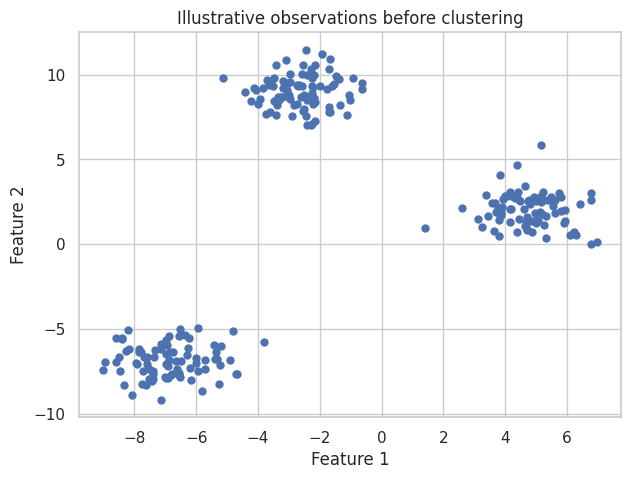

In [ ]:
from sklearn.datasets import make_blobs

X_demo, _ = make_blobs(
    n_samples=250,
    centers=3,
    cluster_std=1.0,
    random_state=RANDOM_STATE
)

plt.figure(figsize=(7, 5))
plt.scatter(X_demo[:, 0], X_demo[:, 1], s=25)
plt.title("Illustrative observations before clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

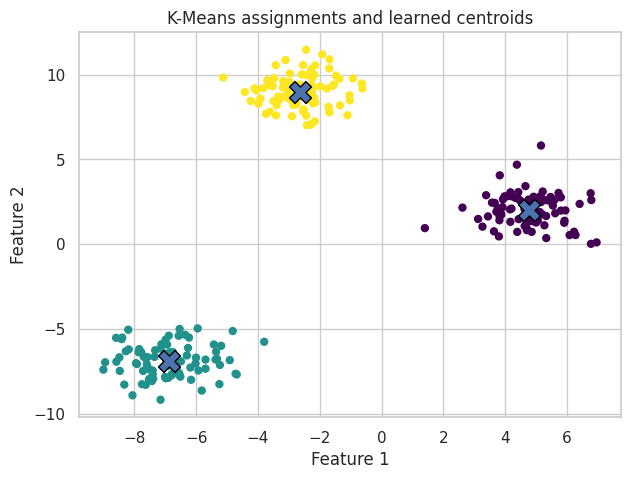

Inertia: 482.11
Iterations: 4


In [ ]:
demo_model = # TODO: Configure K-Means with n_clusters=3, init="random", algorithm="lloyd", n_init=10, random_state=RANDOM_STATE.
demo_labels = demo_model.fit_predict(X_demo)

plt.figure(figsize=(7, 5))
plt.scatter(X_demo[:, 0], X_demo[:, 1], c=demo_labels, cmap="viridis", s=25)
plt.scatter(
    demo_model.cluster_centers_[:, 0],
    demo_model.cluster_centers_[:, 1],
    marker="X", s=250, edgecolor="black"
)
plt.title("K-Means assignments and learned centroids")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

print("Inertia:", round(demo_model.inertia_, 2))
print("Iterations:", demo_model.n_iter_)

### Compare random initialization with K-Means++ on the same illustrative data

Use the existing `X_demo` dataset. To isolate the effect of initialization, keep the dataset, K, and K-Means settings fixed. First visualize the starting centroid positions; then compare the final clustering.

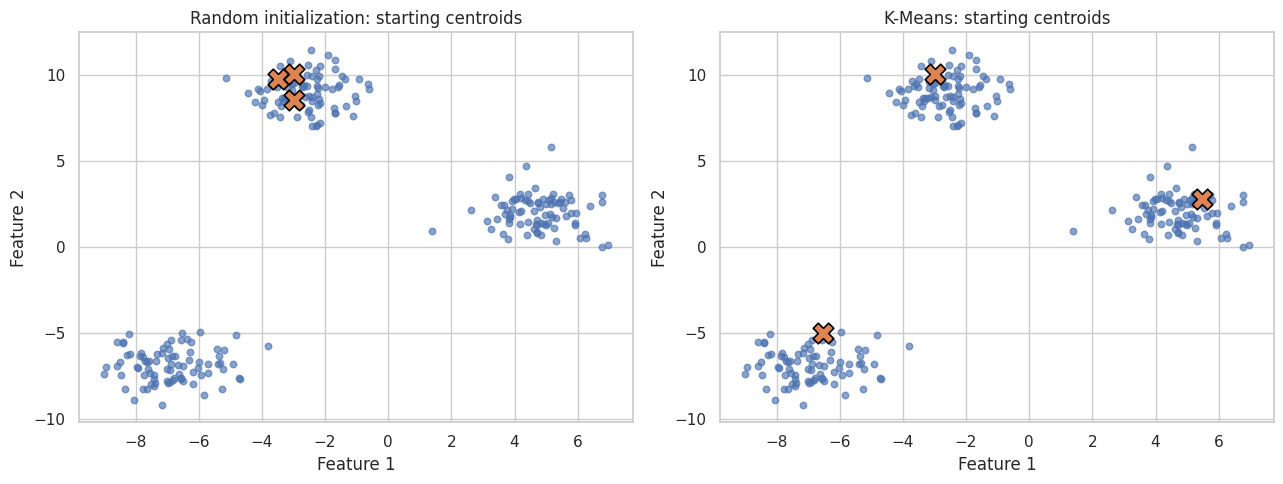

In [ ]:
# Select starting centroids from the same X_demo observations.
K_DEMO = 3
rng_random = np.random.default_rng(RANDOM_STATE)
rng_plus = np.random.default_rng(RANDOM_STATE)

# Random initialization: choose K distinct observations.
random_indices = rng_random.choice(len(X_demo), size=K_DEMO, replace=False)
initial_random = X_demo[random_indices].copy()

# K-Means++ initialization implemented explicitly for learning.
first_index = rng_plus.integers(len(X_demo))
initial_plus = [X_demo[first_index].copy()]

for _ in range(1, K_DEMO):
    distances_sq = np.min(
        np.sum((X_demo[:, None, :] - np.asarray(initial_plus)[None, :, :]) ** 2, axis=2),
        axis=1
    )
    probabilities = distances_sq / distances_sq.sum()
    next_index = rng_plus.choice(len(X_demo), p=probabilities)
    initial_plus.append(X_demo[next_index].copy())

initial_plus = np.asarray(initial_plus)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, centers, title in [
    (axes[0], initial_random, "Random initialization: starting centroids"),
    (axes[1], initial_plus, "K-Means: starting centroids")
]:
    ax.scatter(X_demo[:, 0], X_demo[:, 1], s=22, alpha=0.65)
    ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=220,
               edgecolor="black", linewidth=1.2)
    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

### Visualize centroid movement and compare final outcomes

The next cell records the centroid locations after each update. The paths make it easier to see how the initial positions influence the optimization trajectory. The final inertia values are comparable here because both runs use the same observations and feature space.

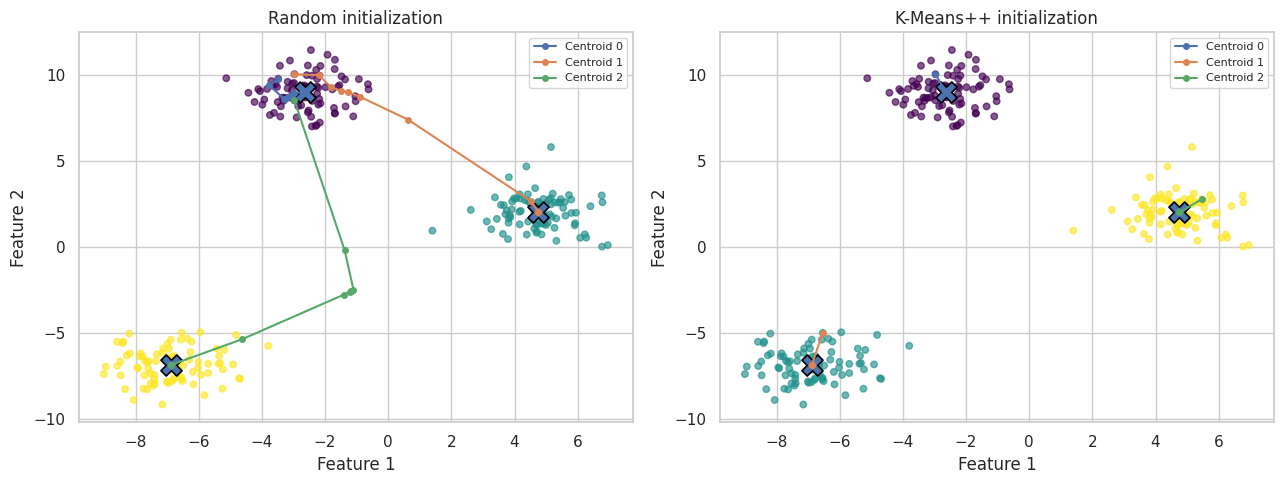

Random initialization — inertia: 482.11; iterations: 9
K-Means++ initialization — inertia: 482.11; iterations: 2


In [ ]:
def run_kmeans_with_centroid_history(X_input, initial_centroids, max_iter=300, tol=1e-4):
    centers = initial_centroids.copy()
    center_history = [centers.copy()]

    for _ in range(max_iter):
        distances = np.linalg.norm(X_input[:, None, :] - centers[None, :, :], axis=2)
        labels = np.argmin(distances, axis=1)
        updated_centers = centers.copy()

        for cluster_id in range(len(centers)):
            members = X_input[labels == cluster_id]
            if len(members) > 0:
                updated_centers[cluster_id] = members.mean(axis=0)

        center_history.append(updated_centers.copy())
        shift = np.linalg.norm(updated_centers - centers)
        centers = updated_centers
        if shift <= tol:
            break

    distances = np.linalg.norm(X_input[:, None, :] - centers[None, :, :], axis=2)
    labels = np.argmin(distances, axis=1)
    inertia = sum(
        np.sum((X_input[labels == j] - centers[j]) ** 2)
        for j in range(len(centers))
    )
    return labels, centers, inertia, center_history

labels_random, centers_random, inertia_random, history_random = run_kmeans_with_centroid_history(
    X_demo, initial_random
)
labels_plus, centers_plus, inertia_plus, history_plus = run_kmeans_with_centroid_history(
    X_demo, initial_plus
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, labels, centers, history, title in [
    (axes[0], labels_random, centers_random, history_random, "Random initialization"),
    (axes[1], labels_plus, centers_plus, history_plus, "K-Means++ initialization")
]:
    ax.scatter(X_demo[:, 0], X_demo[:, 1], c=labels, cmap="viridis", s=22, alpha=0.65)
    path = np.asarray(history)
    for j in range(K_DEMO):
        ax.plot(path[:, j, 0], path[:, j, 1], marker="o", linewidth=1.5,
                markersize=4, label=f"Centroid {j}")
    ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=230,
               edgecolor="black", linewidth=1.2)
    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Random initialization — inertia: {inertia_random:.2f}; iterations: {len(history_random)-1}")
print(f"K-Means++ initialization — inertia: {inertia_plus:.2f}; iterations: {len(history_plus)-1}")

### Check your understanding: initialization

1. Why might random initialization place two centroids close to one another?
2. Why does K-Means++ give distant observations a higher selection probability?
3. Did the two initializations produce the same final centroids and inertia in this run?
4. Does K-Means++ guarantee the globally optimal clustering?

**Important:** A single run is an illustration, not sufficient evidence that one initialization method is always superior. The multi-seed experiment later in this lab provides a more reliable comparison.

### Check your understanding

1. What happens during the assignment step?
2. What happens during the centroid-update step?
3. Why can different initial centroids lead to different solutions?
4. Does cluster label `0` mean better or more important than cluster label `1`?

**Key point:** Cluster IDs are arbitrary identifiers. They do not represent a ranking or the original class names.

## Part 3 — Why feature scaling matters

K-Means uses distances. A feature with a large numerical range can dominate Euclidean distance, even if it is not intrinsically more informative.

We compare K-Means on the original measurements with K-Means on standardized measurements. We use the same $(K=3$) for this controlled demonstration.

In [ ]:
kmeans_raw = # TODO: Configure K-Means with n_clusters=3, init="k-means++", n_init=20, random_state=RANDOM_STATE.
labels_raw = kmeans_raw.fit_predict(X)

scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled_array, columns=X.columns, index=X.index)

kmeans_scaled = KMeans(
    n_clusters=3, init="k-means++", n_init=20,
    random_state=RANDOM_STATE
)
labels_scaled = kmeans_scaled.fit_predict(X_scaled)

print("Raw-data inertia:", round(kmeans_raw.inertia_, 2))
print("Standardized-data inertia:", round(kmeans_scaled.inertia_, 2))
print("Raw-data silhouette:", round(silhouette_score(X, labels_raw), 3))
print("Scaled-data silhouette:", round(silhouette_score(X_scaled, labels_scaled), 3))

Raw-data inertia: 2370689.69
Standardized-data inertia: 1277.93
Raw-data silhouette: 0.571
Scaled-data silhouette: 0.285


**Do not compare the two inertia values directly.** Inertia is measured in the feature space used to fit the model. Its magnitude changes when the feature scales change.

### Discussion

- Did standardization change the cluster assignments?
- Why is a lower raw-data inertia not proof that the raw-data model is better?
- What does `StandardScaler` do to each feature?

For this lab, use the standardized features for all subsequent K-Means experiments.

## Part 4 — Fit the primary K-Means model

We begin with \(K=3\) as a hypothesis to investigate, not as a fact supplied to the algorithm. The value 3 is motivated by the dataset's documented reference classes, but the clustering model does not see those labels.

In [ ]:
kmeans_3 = # TODO: Configure K-Means with n_clusters=3, init="k-means++", n_init=20, max_iter=300, random_state=RANDOM_STATE.

clusters_3 = kmeans_3.fit_predict(X_scaled)

print("Cluster labels:", np.unique(clusters_3))
print("Inertia:", round(kmeans_3.inertia_, 3))
print("Number of iterations:", kmeans_3.n_iter_)
print("Cluster sizes:")
display(pd.Series(clusters_3, name="cluster").value_counts().sort_index())

Cluster labels: [0 1 2]
Inertia: 1277.928
Number of iterations: 7
Cluster sizes:


,count
cluster,
0,65
1,51
2,62


In [ ]:
# Attach the discovered cluster IDs to a copy of the feature table.
clustered_data = X.copy()
clustered_data["cluster"] = clusters_3

display(clustered_data.head(10))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cluster
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,2
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,2
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,2
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,2
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,2
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,2
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,2
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0,2
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0,2
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0,2


### Interpretation questions

1. Are the cluster sizes equal?
2. Does K-Means guarantee equally sized clusters?
3. What does a centroid represent in this dataset?
4. Why should we not call cluster 0 “cultivar 0” yet?

## Part 5 — Choosing K: Elbow Method

Inertia is the sum of squared distances from observations to their assigned centroids. Increasing \(K\) cannot increase the optimal inertia; it generally decreases as more centroids are added.

The Elbow Method plots inertia against \(K\). We look for a point where the reduction in inertia begins to slow. This is a heuristic, not a guaranteed mathematical rule.

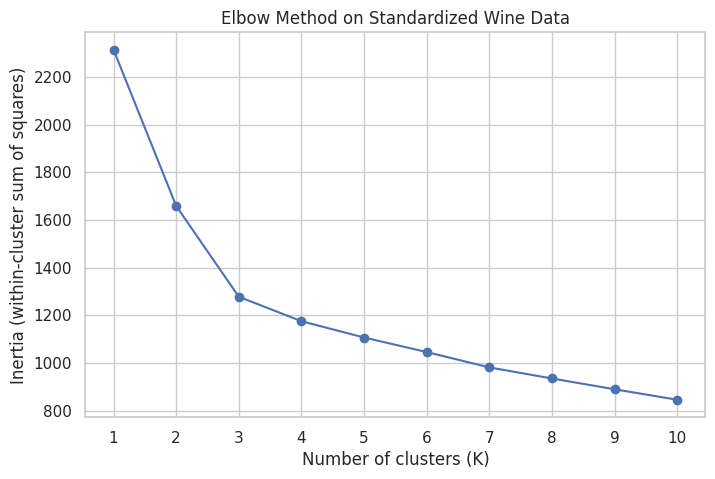

,K,Inertia
0,1,2314.000000
1,2,1658.758852
2,3,1277.928489
3,4,1175.351881
4,5,1107.007343
5,6,1046.002333
6,7,981.595233
7,8,935.201211
8,9,889.892911
9,10,845.895237


In [ ]:
k_values = range(1, 11)
inertias = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        max_iter=300,
        random_state=RANDOM_STATE
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia (within-cluster sum of squares)")
plt.title("Elbow Method on Standardized Wine Data")
plt.show()

display(pd.DataFrame({"K": list(k_values), "Inertia": inertias}))

### Questions

1. Why does inertia decrease as \(K\) increases?
2. Is the elbow always visually clear?
3. What is the danger of choosing \(K=n\)?
4. Based on this plot, which values of \(K\) deserve further investigation?

**Expected observation:** There may not be a single unmistakable elbow. Students should justify a candidate \(K\) rather than claim that the plot proves one exact answer.

## Part 6 — Choosing K: Silhouette Analysis

The silhouette coefficient compares the average distance of a sample to points in its own cluster with the average distance to points in the nearest alternative cluster.

For sample \(i\):

$[
s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))}
$]

- $(a(i)$): mean distance to points in the same cluster.
- $(b(i)$): mean distance to points in the nearest other cluster.

The score ranges from -1 to +1. Larger values generally indicate better-separated, more cohesive clusters. Values near zero suggest overlap; negative values may indicate questionable assignments.

,K,Silhouette Score
0,2,0.259317
1,3,0.284859
2,4,0.258608
3,5,0.231528
4,6,0.237167
5,7,0.203628
6,8,0.157014
7,9,0.149882
8,10,0.143638


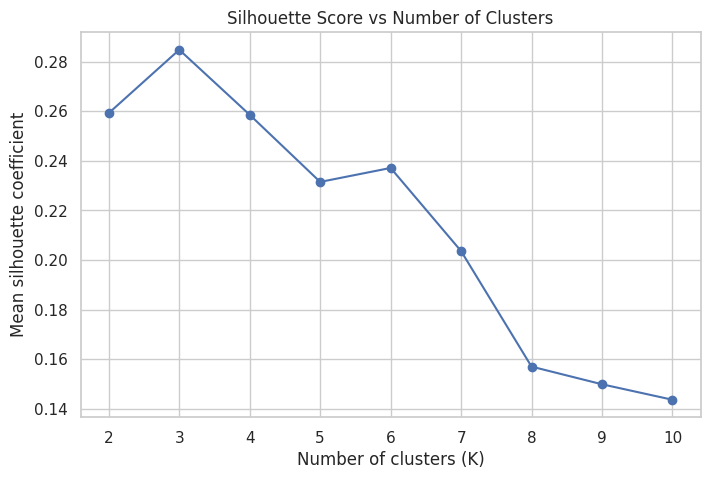

In [ ]:
silhouette_results = []

for k in range(2, 11):
    model = # TODO: Initialize K-Means with n_clusters=k, init="k-means++", n_init=20, max_iter=300, random_state=RANDOM_STATE.
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_results.append((k, score))

silhouette_df = pd.DataFrame(
    silhouette_results, columns=["K", "Silhouette Score"]
)
display(silhouette_df)

plt.figure(figsize=(8, 5))
plt.plot(
    silhouette_df["K"],
    silhouette_df["Silhouette Score"],
    marker="o"
)
plt.xticks(range(2, 11))
plt.xlabel("Number of clusters (K)")
plt.ylabel("Mean silhouette coefficient")
plt.title("Silhouette Score vs Number of Clusters")
plt.show()

### Compare the two selection methods

1. Does the best silhouette score occur at the same \(K\) suggested by the elbow?
2. Why can the two methods disagree?
3. Should the highest silhouette score automatically determine the final \(K\)?
4. What other considerations (interpretability, domain knowledge, cluster size, stability) should influence the decision?

**Important:** Silhouette analysis is an internal metric. It evaluates separation and cohesion in the feature space; it does not tell us whether the clusters correspond to meaningful real-world categories.

## Part 7 — Visualizing 13 dimensions using PCA

The Wine dataset has 13 features, so it cannot be plotted directly in a two-dimensional scatter plot. Principal Component Analysis (PCA) projects the standardized features onto directions that capture as much variance as possible.

PCA is used here for visualization.

PCA-based K-Means training completed!
Number of clusters: 3
Number of iterations: 5
Inertia: 259.509


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,PC1,PC2,Predicted_Cluster
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,3.316751,1.443463,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,2.209465,-0.333393,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,2.516740,1.031151,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,3.757066,2.756372,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,1.008908,0.869831,0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,3.050254,2.122401,0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,2.449090,1.174850,0
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0,2.059437,1.608963,0
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0,2.510874,0.918071,0
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0,2.753628,0.789438,0


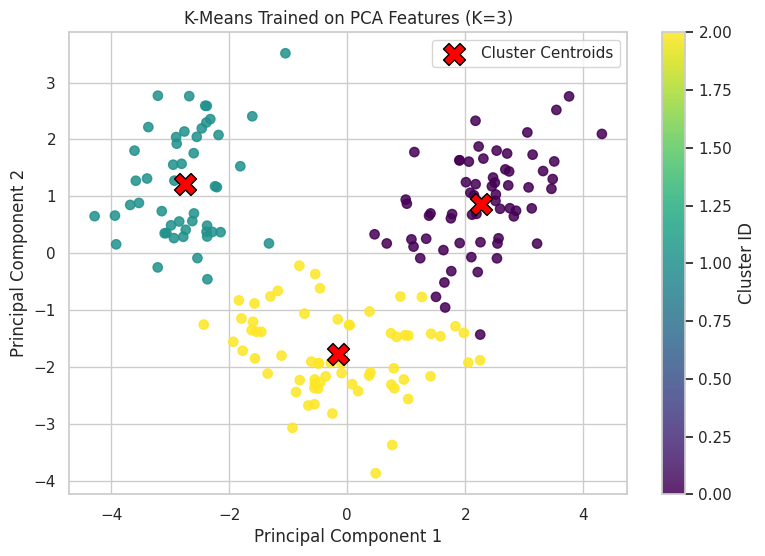

Predictions for new observations:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Predicted_Cluster
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0


In [ ]:

# ==========================================
# K-MEANS MODEL TRAINING USING PCA FEATURES
# ==========================================

# 1. Select number of clusters
final_k = 3

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

# 2. Initialize K-Means model
pca_kmeans_model = # TODO: Configure K-Means with n_clusters=final_k, init="k-means++", n_init=20, max_iter=300, random_state=RANDOM_STATE.

# 3. Train model using PCA-transformed features
pca_kmeans_model.fit(X_pca)

print("PCA-based K-Means training completed!")
print("Number of clusters:", pca_kmeans_model.n_clusters)
print("Number of iterations:", pca_kmeans_model.n_iter_)
print("Inertia:", round(pca_kmeans_model.inertia_, 3))


# 4. Predict clusters for existing observations
pca_clusters = pca_kmeans_model.predict(X_pca)

# 5. Store cluster assignments
pca_results = X.copy()
pca_results["PC1"] = X_pca[:, 0]
pca_results["PC2"] = X_pca[:, 1]
pca_results["Predicted_Cluster"] = pca_clusters

display(pca_results.head(10))


# 6. Visualize predicted clusters
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=pca_clusters,
    cmap="viridis",
    s=45,
    alpha=0.85
)

# Plot learned centroids
centroids = pca_kmeans_model.cluster_centers_

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=250,
    c="red",
    edgecolors="black",
    label="Cluster Centroids"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"K-Means Trained on PCA Features (K={final_k})")
plt.colorbar(scatter, label="Cluster ID")
plt.legend()
plt.show()


# 7. Predict cluster for new unseen observations
# Use raw observations with the original feature columns.

new_samples = X.iloc[:3].copy()

# Apply the already-fitted scaler
new_samples_scaled = scaler.transform(new_samples)

# Apply the already-fitted PCA transformation
new_samples_pca = pca.transform(new_samples_scaled)

# Predict using PCA-trained K-Means
new_predictions = pca_kmeans_model.predict(new_samples_pca)

new_results = new_samples.copy()
new_results["Predicted_Cluster"] = new_predictions

print("Predictions for new observations:")
display(new_results)


### Interpretation

- Are the clusters visually separated?
- Is there overlap?
- Does the two-dimensional projection preserve all 13-dimensional distances?
- Why can a plot look separated even though the full feature-space clustering is less clear?

Do not interpret PCA axes as individual original chemical measurements.

## Part 8 — Limitations and extension challenge

K-Means works best when clusters are reasonably compact and approximately spherical in the chosen feature space. It can struggle with:

- Non-spherical or curved clusters.
- Clusters with substantially different densities or sizes.
- Strong outliers, which can pull centroids.
- Poor feature scaling or irrelevant features.
- A poorly selected value of \(K\).

K-Means++ improves the initial centroid selection, but it does not remove these limitations. In particular, it does not:

- Automatically determine the correct number of clusters.
- Guarantee the global optimum.
- Make K-Means robust to outliers.
- Make K-Means suitable for non-spherical or curved clusters.
- Resolve clusters with substantially different densities or sizes.
- Eliminate the need for meaningful features and appropriate scaling.

### Extension challenge: demonstrate a failure case

Use the two-moons dataset. Compare K-Means with the visual structure of the data. The aim is to understand that an algorithm can execute successfully while its assumptions are unsuitable for the data.

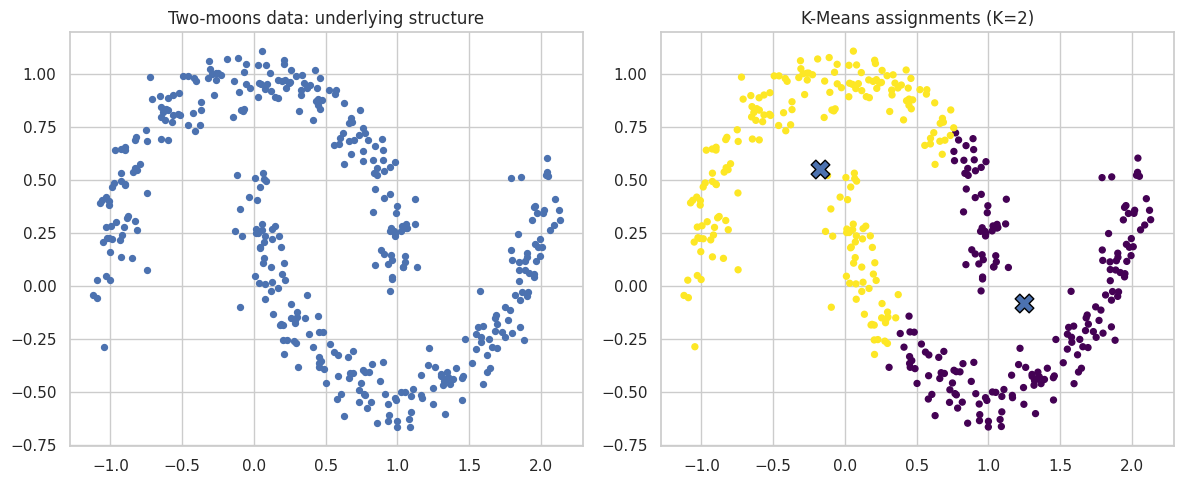

In [ ]:
from sklearn.datasets import make_moons

X_moons, _ = make_moons(
    n_samples=400,
    noise=0.08,
    random_state=RANDOM_STATE
)

moon_model = # TODO: Initialize K-Means with n_clusters=2, n_init=20, random_state=RANDOM_STATE.
moon_labels = moon_model.fit_predict(X_moons)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X_moons[:, 0], X_moons[:, 1], s=18)
axes[0].set_title("Two-moons data: underlying structure")

axes[1].scatter(
    X_moons[:, 0], X_moons[:, 1],
    c=moon_labels, cmap="viridis", s=18
)
axes[1].scatter(
    moon_model.cluster_centers_[:, 0],
    moon_model.cluster_centers_[:, 1],
    marker="X", s=180, edgecolor="black"
)
axes[1].set_title("K-Means assignments (K=2)")

plt.tight_layout()
plt.show()

### Extension questions

1. Why does K-Means divide the curved moons in a way that may not match the visible structure?
2. Would increasing \(K\) necessarily solve the underlying problem?
3. Which clustering family would you investigate for non-convex or density-based structures?

Hint: investigate DBSCAN and Spectral Clustering after this laboratory.

## Final checklist

1. Dataset dimensions, feature summary, and missing-value check.
2. Evidence showing why scaling matters.
3. K-Means model configuration and cluster sizes.
4. Elbow plot and your justified candidate \(K\).
5. Silhouette plot and comparison with the elbow method.
6. PCA visualization with a clear explanation of its role.
7. Cluster profile table and heatmap with written interpretation.
8. ARI, AMI, NMI, and contingency table after revealing reference labels.
9. Initial-centroid plots for random initialization and K-Means++.
10. Centroid movement visualization and comparison of final inertia.
11. Multi-seed comparison of random initialization and K-Means++.
12. Initialization stability table.
13. Two-moons failure-case visualization and explanation.

##assessment questions

1. Is K-Means supervised or unsupervised? Explain.
2. Why is scaling important for K-Means?
3. What is a centroid?
4. What does inertia measure?
5. Why does inertia not independently identify the optimal \(K\)?
6. What does a negative silhouette coefficient suggest?
7. Why are cluster labels arbitrary?
8. Why are ARI and AMI suitable for comparing cluster assignments?
9. Why should reference labels be withheld until external evaluation?
10. Give two cases in which K-Means may not be appropriate.

## Dataset and technical references

1. UCI Machine Learning Repository — Wine: https://archive.ics.uci.edu/dataset/109/wine
2. Scikit-learn — K-Means documentation: https://scikit-learn.org/stable/modules/clustering.html#k-means
3. Scikit-learn — Wine dataset description: https://scikit-learn.org/stable/datasets/toy_dataset.html#wine-dataset
4. Scikit-learn — Clustering performance evaluation: https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation
5. Scikit-learn — Adjusted Rand Index: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html
6. Scikit-learn — Silhouette score: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html

**Dataset citation:** Aeberhard, S. & Forina, M. (1992). *Wine*. UCI Machine Learning Repository. https://doi.org/10.24432/C5PC7J